# Linear Regression Experiment

**Goal:** model the relationship between city population and restaurant profit.

The notebook implements and evaluates single-variable linear regression with full-batch gradient descent.


In [1]:
from copy import deepcopy
from math import ceil
from typing import Callable, List, Tuple

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


## 1. Data

The feature represents city population in units of 10,000 people. The target is average monthly profit in units of $10,000.


In [2]:
def load_data(filepath: str) -> Tuple[np.ndarray, np.ndarray]:
    """Load a two-column CSV dataset containing feature and target values."""
    data = np.loadtxt(filepath, delimiter=",")
    return data[:, 0], data[:, 1]


filepath = "data/ex1data1.txt"
x_train, y_train = load_data(filepath)

print(f"Training examples: {x_train.size}")
print(f"Feature shape: {x_train.shape}")
print(f"Target shape: {y_train.shape}")
print(f"Population sample: {x_train[:5]}")
print(f"Profit sample: {y_train[:5]}")


Training examples: 97
Feature shape: (97,)
Target shape: (97,)
Population sample: [6.1101 5.5277 8.5186 7.0032 5.8598]
Profit sample: [17.592   9.1302 13.662  11.854   6.8233]


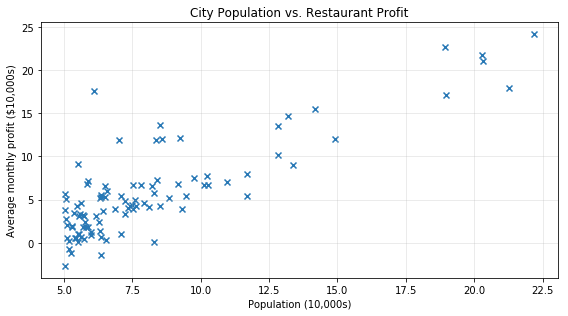

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x_train, y_train, marker="x", color="#2878B5", label="Observed")
ax.set_title("City Population vs. Restaurant Profit")
ax.set_xlabel("Population (10,000s)")
ax.set_ylabel("Average monthly profit ($10,000s)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 2. Model and Cost Function

For parameters $w$ and $b$, the prediction is $f_{w,b}(x)=wx+b$. The training objective is mean squared error scaled by one half.


In [4]:
def compute_cost(x: np.ndarray, y: np.ndarray, w: float, b: float) -> float:
    """Compute half mean squared error for a linear regression model."""
    residuals = w * x + b - y
    return float((residuals @ residuals) / (2.0 * x.size))


def compute_gradient(x: np.ndarray, y: np.ndarray, w: float, b: float) -> Tuple[float, float]:
    """Compute gradients of the cost with respect to weight and bias."""
    residuals = w * x + b - y
    dj_dw = float((residuals @ x) / x.size)
    dj_db = float(residuals.mean())
    return dj_dw, dj_db


print(f"Initial cost: {compute_cost(x_train, y_train, 0.0, 0.0):.4f}")


Initial cost: 32.0727


## 3. Gradient Descent

Full-batch gradient descent updates both parameters using every training example at each iteration.


In [5]:
CostFunction = Callable[[np.ndarray, np.ndarray, float, float], float]
GradientFunction = Callable[[np.ndarray, np.ndarray, float, float], Tuple[float, float]]


def gradient_descent(
    x: np.ndarray,
    y: np.ndarray,
    initial_w: float,
    initial_b: float,
    cost_function: CostFunction,
    gradient_function: GradientFunction,
    learning_rate: float,
    iterations: int,
) -> Tuple[float, float, List[float], List[Tuple[float, float]]]:
    """Train a linear regression model with full-batch gradient descent."""
    w = deepcopy(initial_w)
    b = initial_b
    cost_history: List[float] = []
    parameter_history: List[Tuple[float, float]] = []
    log_interval = max(1, ceil(iterations / 10))

    for iteration in range(iterations):
        dj_dw, dj_db = gradient_function(x, y, w, b)
        w -= learning_rate * dj_dw
        b -= learning_rate * dj_db
        cost_history.append(cost_function(x, y, w, b))

        if iteration % log_interval == 0 or iteration == iterations - 1:
            parameter_history.append((float(w), float(b)))
            print(f"Iteration {iteration:4d} | Cost {cost_history[-1]:8.4f}")

    return float(w), float(b), cost_history, parameter_history


learning_rate = 0.01
iterations = 1500
w, b, J_history, parameter_history = gradient_descent(
    x=x_train,
    y=y_train,
    initial_w=0.0,
    initial_b=0.0,
    cost_function=compute_cost,
    gradient_function=compute_gradient,
    learning_rate=learning_rate,
    iterations=iterations,
)

print(f"Learned weight: {w:.6f}")
print(f"Learned bias: {b:.6f}")


Iteration    0 | Cost   6.7372
Iteration  150 | Cost   5.3114
Iteration  300 | Cost   4.9626
Iteration  450 | Cost   4.7596
Iteration  600 | Cost   4.6415
Iteration  750 | Cost   4.5727
Iteration  900 | Cost   4.5327
Iteration 1050 | Cost   4.5094
Iteration 1200 | Cost   4.4958
Iteration 1350 | Cost   4.4880
Iteration 1499 | Cost   4.4834
Learned weight: 1.166362
Learned bias: -3.630291


## 4. Diagnostics

A healthy training run has a cost that decreases monotonically and approaches a stable value.


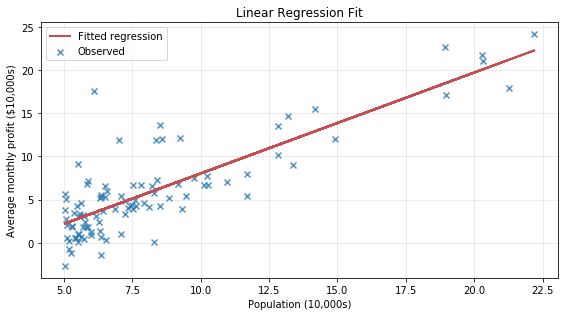

In [6]:
predicted = w * x_train + b

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x_train, y_train, marker="x", color="#2878B5", alpha=0.8, label="Observed")
ax.plot(x_train, predicted, color="#C44E52", linewidth=2, label="Fitted regression")
ax.set_title("Linear Regression Fit")
ax.set_xlabel("Population (10,000s)")
ax.set_ylabel("Average monthly profit ($10,000s)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Learning Curve

This curve plots the training cost recorded in `J_history` after every gradient-descent iteration.


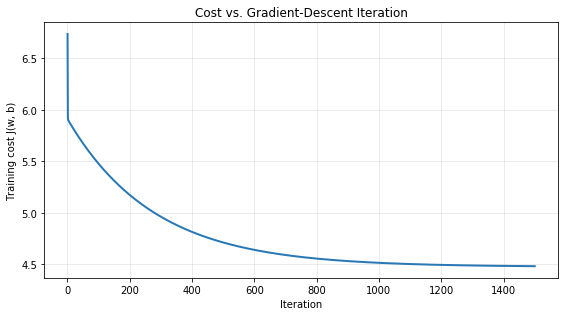

Initial cost: 6.7372
Final cost: 4.4834
Cost reduction: 2.2538


In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(J_history) + 1), J_history, color="#2878B5", linewidth=2)
ax.set_title("Cost vs. Gradient-Descent Iteration")
ax.set_xlabel("Iteration")
ax.set_ylabel("Training cost J(w, b)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Initial cost: {J_history[0]:.4f}")
print(f"Final cost: {J_history[-1]:.4f}")
print(f"Cost reduction: {J_history[0] - J_history[-1]:.4f}")
